# Modelo VAEP Atômico Enriquecido com Features de Tracking

Este notebook implementa e avalia um modelo de valoração de ações no futebol (VAEP - Valuing Actions by Estimating Probabilities) com uma abordagem híbrida, combinando dados de evento (SPADL) com features extraídas de dados de tracking.

## Fluxo de Trabalho Experimental

O processo é dividido em **três grandes etapas** para permitir uma comparação justa e clara do impacto das features de tracking:

### 1. Modelo VAEP Baseline
- **Objetivo:** Estabelecer uma linha de base de performance.
- **Metodologia:** Um modelo VAEP atômico padrão é treinado utilizando exclusivamente features derivadas dos dados de evento SPADL. Este modelo serve como nosso ponto de referência.

### 2. Classificador de Sucesso Enriquecido
- **Objetivo:** Prever a probabilidade de uma ação ser bem-sucedida, utilizando um contexto tático que não está presente nos dados de evento.
- **Metodologia:**
    - Extraímos features de **`compactação defensiva`**, **`pressão`**, **`triangulação de chute`** e **`velocidade`** dos dados de tracking para cada ação.
    - Um classificador (XGBoost) é treinado para prever o sucesso de uma ação (`result_name`). As suas features de entrada são as features SPADL padrão **MAIS** as features extraídas dos dados de tracking.
    - A performance deste classificador é avaliada para garantir que ele aprendeu padrões significativos.

### 3. Modelo VAEP Final (Híbrido)
- **Objetivo:** Avaliar o impacto de um classificador de sucesso "mais inteligente" na performance final do VAEP.
- **Metodologia:**
    - O classificador treinado na Etapa 2 é usado para gerar uma nova feature: `success_score` (a probabilidade de sucesso da ação).
    - Um novo modelo VAEP é treinado. Suas features de entrada são as features SPADL padrão **MAIS** a feature `success_score`.
    - A performance deste modelo final é comparada com o VAEP Baseline para quantificar o ganho obtido ao incorporar o contexto dos dados de tracking de forma indireta (através do classificador).

Ao final, o notebook gera os valores de VAEP para os jogadores e plota gráficos de diagnóstico detalhados para os modelos finais.

In [81]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.metrics import brier_score_loss
from socceraction.atomic.spadl import convert_to_atomic
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, roc_auc_score
import seaborn as sns
import os

In [82]:
import warnings
warnings.filterwarnings('ignore')

---

## Carregando dados de Evento e Transformação para Atomic SPADL

In [83]:
df_spadl = pd.read_parquet('spadl_events/spadl_ltr2.parquet')
df_spadl.head()

df_spadl['start_x'] = df_spadl['start_x'] * 105.0
df_spadl['start_y'] = df_spadl['start_y'] * 68.0
df_spadl['end_x'] = df_spadl['end_x'] * 105.0
df_spadl['end_y'] = df_spadl['end_y'] * 68.0

In [84]:
## Mantendo apenas a primeira linha de cada event_id

df_spadl = df_spadl.sort_values(by='time_seconds').drop_duplicates(subset=['original_event_id'], keep = 'first')

df_spadl['result_name'] = df_spadl['result_id'].map({
    1: 'success',
    0: 'fail'
})

In [85]:
# Ordenar ações por tempo dentro de cada jogo
df_spadl = df_spadl.sort_values(by=['game_id', 'period_id', 'time_seconds', 'action_id']).reset_index(drop=True)

In [86]:
df_spadl.shape

(299683, 17)

## Conversão de SPADL para Atomic SPADL

In [87]:
df_atomic = convert_to_atomic(df_spadl)
df_atomic = df_atomic[df_atomic['original_event_id'].notna()]
df_atomic.head()


,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id
0,13335,12926009.0,0,1,153.887,5.0,15620,52.826,34.309,-18.499,-4.643,0,5
1,13335,12926009.0,1,1,155.255,5.0,4696,34.327,29.666,0.000,0.000,23,0
2,13335,12926647.0,2,1,156.623,5.0,4696,34.623,31.107,45.198,18.914,0,5
3,13335,12926642.0,3,1,159.860,5.0,14278,79.821,50.021,NaN,NaN,9,0
4,13335,20246849.0,4,1,159.893,11.0,284,25.179,17.979,18.809,-10.268,18,0


In [88]:
df_atomic.sort_values(by=['x'])

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id
408633,13542,27296881.0,408633,1,810.4770,17.0,8074,0.0,66.390,0.0,0.0,10,0
396026,13537,16649597.0,396026,1,1762.3790,119.0,5063,0.0,67.586,0.0,0.0,10,0
396030,13537,16649702.0,396030,1,1814.5145,119.0,5063,0.0,67.807,0.0,0.0,10,0
120573,13425,15279359.0,120573,2,5765.0650,15.0,521,0.0,51.585,0.0,0.0,10,0
424745,13549,17058751.0,424745,1,2171.5380,17.0,12785,0.0,34.677,NaN,NaN,14,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
600990,13621,18803142.0,600990,2,5545.5460,218.0,7269,NaN,NaN,NaN,NaN,27,4
601071,13621,18803498.0,601071,2,5791.4750,218.0,7328,NaN,NaN,NaN,NaN,10,0
601073,13621,18803512.0,601073,2,5825.2420,218.0,7328,NaN,NaN,NaN,NaN,23,0
601075,13621,35050274.0,601075,2,5844.2440,218.0,7658,NaN,NaN,NaN,NaN,9,0


Adicionar a coluna `type_name` ao Atomic SPADL:

In [89]:
from socceraction.atomic.spadl.config import actiontypes as atomic_actiontypes

# Garante que o df_atomic.type_id só tenha valores válidos
max_atomic_id = len(atomic_actiontypes) - 1

df_atomic['type_name'] = df_atomic['type_id'].apply(
    lambda x: atomic_actiontypes[x] if 0 <= x <= max_atomic_id
              else f"unknown_{x}"
)

---

## Preparar dados para o Classificador de Sucesso

Carrega as features de tracking e prepara os dados para o classificador de sucesso:

In [90]:
df = pd.read_parquet('tracking_features/triangle/parquets_triangle/13335.parquet')
df

,match_id,possession_id,num_defensores_no_triangulo
0,13335,12926009,1
1,13335,12926647,1
2,13335,12926643,1
3,13335,12926642,1
4,13335,12926648,1
...,...,...,...
1343,13335,12948011,0
1344,13335,12948017,2
1345,13335,12948027,1
1346,13335,12948032,2


In [91]:
print("Iniciando a integração das features de tracking...")

# Agora pode ser uma lista de caminhos de pasta
pastas_features_compaction = [
    'tracking_features/compaction/parquets_compaction',
    'tracking_features/speed/parquets_speed', 
    'tracking_features/pression/parquets_tracking_features',
    'tracking_features/triangle/parquets_triangle',
    'tracking_features/angle_keeper/parquets_gk_angle'
]

# Dicionário para armazenar os dataframes de cada pasta
dfs_por_pasta = {}

for pasta in pastas_features_compaction:
    nome_variavel = os.path.basename(pasta).replace('.', '_')
    lista_dfs = []
    
    arquivos_features = [f for f in os.listdir(pasta) if f.endswith('.parquet')]
    
    for nome_arquivo in tqdm(arquivos_features, desc=f"Carregando features de {nome_variavel}"):
        caminho = os.path.join(pasta, nome_arquivo)
        lista_dfs.append(pd.read_parquet(caminho))
    
    df_merged = pd.concat(lista_dfs, ignore_index=True)
    df_merged.rename(columns={'possession_id': 'original_event_id'}, inplace=True)
    df_merged['original_event_id'] = df_merged['original_event_id'].astype(float).astype(int).astype(str)

    #renomear match id para game_id
    if nome_variavel == 'parquets_triangle':
        df_merged.rename(columns={'match_id': 'game_id'}, inplace=True)

    df_merged['game_id'] = df_merged['game_id'].astype(int)
    
    dfs_por_pasta[nome_variavel] = df_merged
    print(f"Features da pasta '{pasta}' carregadas com sucesso.\n")

# Exemplo: acessar os DataFrames gerados
for nome, df in dfs_por_pasta.items():
    print(f"DataFrame da pasta '{nome}' (5 primeiras linhas):")
    display(df.head())

Iniciando a integração das features de tracking...


Carregando features de parquets_compaction:   0%|          | 0/233 [00:00<?, ?it/s]

Carregando features de parquets_compaction: 100%|██████████| 233/233 [00:00<00:00, 409.59it/s]


Features da pasta 'tracking_features/compaction/parquets_compaction' carregadas com sucesso.



Carregando features de parquets_speed: 100%|██████████| 233/233 [00:00<00:00, 448.77it/s]


Features da pasta 'tracking_features/speed/parquets_speed' carregadas com sucesso.



... (11 outputs left out)

DataFrame da pasta 'parquets_triangle' (5 primeiras linhas):


,game_id,original_event_id,num_defensores_no_triangulo
0,13335,12926009,1.0
1,13335,12926647,1.0
2,13335,12926643,1.0
3,13335,12926642,1.0
4,13335,12926648,1.0


DataFrame da pasta 'parquets_gk_angle' (5 primeiras linhas):


,game_id,original_event_id,gk_angle_off_center
0,13335,12926009,3.094883
1,13335,12926647,2.625969
2,13335,12926643,2.299050
3,13335,12926642,2.299050
4,13335,12926648,0.638047


Adiciona coluna `result_name` ao Atomic SPADL:


In [92]:
df_atomic['original_event_id'] = df_atomic['original_event_id'].astype(str)
events_results = df_spadl.sort_values(by='time_seconds')[['original_event_id', 'result_name']].drop_duplicates(subset=['original_event_id'])
events_results['original_event_id'] = events_results['original_event_id'].astype(str)
df_atomic = df_atomic.merge(events_results, on='original_event_id', how='left')

df_atomic.head()

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id,type_name,result_name
0,13335,12926009.0,0,1,153.887,5.0,15620,52.826,34.309,-18.499,-4.643,0,5,pass,success
1,13335,12926009.0,1,1,155.255,5.0,4696,34.327,29.666,0.000,0.000,23,0,receival,success
2,13335,12926647.0,2,1,156.623,5.0,4696,34.623,31.107,45.198,18.914,0,5,pass,fail
3,13335,12926642.0,3,1,159.860,5.0,14278,79.821,50.021,NaN,NaN,9,0,tackle,fail
4,13335,20246849.0,4,1,159.893,11.0,284,25.179,17.979,18.809,-10.268,18,0,clearance,success


---

# Features e Labels para o Classificador de Sucesso

In [93]:
import socceraction.atomic.spadl as atomicspadl
import socceraction.atomic.vaep.features as fs
import socceraction.atomic.vaep.labels as lab
import socceraction.atomic.vaep.formula as fm

### Features

In [94]:
# ==========================
# 2. FEATURES ATOMIC
# ==========================

xfns = [
    fs.actiontype_onehot, fs.bodypart_onehot,
    fs.goalscore, fs.location, fs.polar,
    fs.direction, fs.team, fs.time, fs.time_delta,
]
nb_prev_actions = 3
Xcols = fs.feature_column_names(xfns, nb_prev_actions)

X_parts = []
for gid in tqdm(df_atomic.game_id.unique(), desc="Features"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    states = fs.gamestates(acts, nb_prev_actions)
    X_parts.append(pd.concat([fn(states) for fn in xfns], axis=1)[Xcols])
features = pd.concat(X_parts).reset_index(drop=True).fillna(0)


Features: 100%|██████████| 232/232 [00:12<00:00, 18.02it/s]


### Labels

In [95]:
import socceraction.atomic.vaep.labels as lab

Ycols = ["scores","concedes","result_name"]
Y_parts = []

for gid in tqdm(df_atomic.game_id.unique(), desc="Labels"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    Y_parts.append(pd.concat([lab.scores(acts), lab.concedes(acts), acts['result_name']], axis=1)[Ycols])
labels = pd.concat(Y_parts).reset_index(drop=True)

Labels:   0%|          | 0/232 [00:00<?, ?it/s]

Labels: 100%|██████████| 232/232 [00:08<00:00, 28.36it/s]


In [96]:
# Garante que features e labels têm o mesmo índice sequencial do df_atomic
features = features.reset_index(drop=True)
labels   = labels.reset_index(drop=True)

# Checagem de sanidade: todos os comprimentos batem?
assert len(features) == len(labels) == len(df_atomic), (
    f"Desalinhamento de índices: "
    f"df_atomic={len(df_atomic)}, features={len(features)}, labels={len(labels)}"
)


In [97]:
mask_goal = features['actiontype_goal_a0'] == True

# Remover as linhas que contêm gols
features = features[~mask_goal]
labels = labels[~mask_goal]
features.shape, labels.shape

((520061, 142), (520061, 3))

In [98]:
labels['result_name'] = labels['result_name'].replace({'success': 1, 'fail': 0})

In [99]:
# remove também as linhas que contêm gols de df_atomic
print(f"Antes de remover gols: {df_atomic.shape}")
df_atomic = df_atomic[df_atomic.type_name != 'goal'].reset_index(drop=True)
print(f"Depois de remover gols: {df_atomic.shape}")

Antes de remover gols: (520884, 15)
Depois de remover gols: (520061, 15)


In [100]:
# Célula de Verificação: Taxa de Sucesso Real dos Chutes
df_chutes = df_atomic[df_atomic['type_name'] == 'shot']
taxa_de_sucesso_real = df_chutes['result_name'].value_counts(normalize=True)

print("Taxa de sucesso real para ações do tipo 'shot':")
print(taxa_de_sucesso_real)

Taxa de sucesso real para ações do tipo 'shot':
result_name
fail       0.874236
success    0.125764
Name: proportion, dtype: float64


In [101]:
# teste rápido de alinhamento
assert len(df_atomic) == features.shape[0] == labels.shape[0], "Indices desalinhados!"

---

## Divisão Treino/Teste

In [102]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(
    gss.split(df_atomic, groups=df_atomic.game_id)
)

mask_train = df_atomic.index.isin(train_idx)
mask_test  = df_atomic.index.isin(test_idx)


# Separar as características (X) e os rótulos (y) com base nas máscaras
X_train = features[mask_train].reset_index(drop=True)
X_test  = features[mask_test].reset_index(drop=True)

y_train = labels[mask_train].reset_index(drop=True)
y_test  = labels[mask_test].reset_index(drop=True)

---

# Classificador - Score de Sucesso

### Enriquecimento - Features de Tracking
Enriquecimento com as features extraídas dos dados de tracking.

In [103]:
print("Enriquecendo conjuntos de dados para o classificador...")

# Garante que os tipos das chaves em df_atomic são os corretos para o merge
df_atomic['original_event_id'] = df_atomic['original_event_id'].astype(float).astype(int).astype(str)
df_atomic['game_id'] = df_atomic['game_id'].astype(int)

# Função auxiliar para enriquecer um conjunto de dados X com múltiplos dataframes de features
def enrich_features(X_original, mask, dfs_features):
    keys = df_atomic[mask][['game_id', 'original_event_id']].reset_index(drop=True)
    X_enriched = X_original.reset_index(drop=True)

    for nome_df, df_feat in dfs_features.items():
        # Identifica as colunas de features, excluindo colunas de chave
        colunas_excluir = {'original_event_id', 'game_id'}
        colunas_features = [col for col in df_feat.columns if col not in colunas_excluir]

        if not colunas_features:
            print(f"Aviso: Nenhuma feature utilizável encontrada em '{nome_df}'")
            continue

        # Realiza o merge usando apenas as colunas de features
        merged_features = pd.merge(
            keys,
            df_feat,
            on=['game_id', 'original_event_id'],
            how='left'
        ).fillna(0)

        # Remove as colunas de chave do resultado final e prefixa as features
        merged_features = merged_features[colunas_features]

        # Concatena com o DataFrame original
        X_enriched = pd.concat([X_enriched, merged_features], axis=1)

    return X_enriched

# Aplica a função usando todos os DataFrames em dfs_por_pasta
X_train_enriquecido = enrich_features(X_train, mask_train, dfs_por_pasta)
X_test_enriquecido = enrich_features(X_test, mask_test, dfs_por_pasta)

print("Conjuntos de dados enriquecidos criados: X_train_enriquecido, X_test_enriquecido.")
display(X_train_enriquecido.head())


Enriquecendo conjuntos de dados para o classificador...
Conjuntos de dados enriquecidos criados: X_train_enriquecido, X_test_enriquecido.


,actiontype_pass_a0,actiontype_cross_a0,actiontype_throw_in_a0,actiontype_freekick_crossed_a0,actiontype_freekick_short_a0,actiontype_corner_crossed_a0,actiontype_corner_short_a0,actiontype_take_on_a0,actiontype_foul_a0,actiontype_tackle_a0,...,defensive_compaction_y,player_speed,avg_teammate_speed_10m,num_defensores_raio_3_metros,num_defensores_raio_6_metros,num_companheiros_raio_8_metros,pressao_posicional_ponderada,num_linhas_passe_abertas,num_defensores_no_triangulo,gk_angle_off_center
0,True,False,False,False,False,False,False,False,False,False,...,14.339360,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,1.0,3.094883
1,False,False,False,False,False,False,False,False,False,False,...,14.339360,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,1.0,3.094883
2,True,False,False,False,False,False,False,False,False,False,...,14.413517,0.000000,0.00000,0.0,1.0,0.0,0.547016,6.0,1.0,2.625969
3,False,False,False,False,False,False,False,False,False,True,...,10.825132,5.324247,8.74152,1.0,2.0,3.0,1.447241,2.0,1.0,2.299050
4,False,False,False,False,False,False,False,False,False,False,...,0.000000,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000


In [104]:
# Ajuste Específico para a Feature 'gk_angle_off_center'
# Como a feature `gk_angle_off_center` só é relevante para chutes, vamos atribuir um valor de -1 para todas as outras ações. Isso permite que o modelo aprenda a tratar os chutes de forma diferente.

feature_col = 'gk_angle_off_center'

# Verifica se a coluna foi adicionada corretamente
if feature_col in X_train_enriquecido.columns:
    print(f"Ajustando a feature '{feature_col}'...")

    # Identifica as ações que NÃO são chutes no conjunto de treino e atribui -1
    shot_mask_train = X_train_enriquecido['actiontype_shot_a0'] == 1
    X_train_enriquecido.loc[~shot_mask_train, feature_col] = -1

    # Faz o mesmo para o conjunto de teste para manter a consistência
    shot_mask_test = X_test_enriquecido['actiontype_shot_a0'] == 1
    X_test_enriquecido.loc[~shot_mask_test, feature_col] = -1

    print("Feature 'gk_angle_off_center' ajustada para -1 em todas as ações que não são chutes.")

    # Exemplo para verificação
    print("\nExemplo de passes com valor -1:")
    display(X_train_enriquecido[~shot_mask_train][['actiontype_pass_a0', feature_col]].head())
    
    print("\nExemplo de chutes com valor de ângulo original:")
    display(X_train_enriquecido[shot_mask_train][[feature_col]].head())
else:
    print(f"Aviso: A coluna '{feature_col}' não foi encontrada nos dataframes enriquecidos.")

Ajustando a feature 'gk_angle_off_center'...
Feature 'gk_angle_off_center' ajustada para -1 em todas as ações que não são chutes.

Exemplo de passes com valor -1:


,actiontype_pass_a0,gk_angle_off_center
0,True,-1.0
1,False,-1.0
2,True,-1.0
3,False,-1.0
4,False,-1.0



Exemplo de chutes com valor de ângulo original:


,gk_angle_off_center
79,18.515750
116,1.944045
224,0.000000
333,0.118653
375,5.991981


### Avaliar quais os melhores parâmetros para o classificador

In [105]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

# Não executar a busca de hiperparâmetros se não for necessário
if False:
    scale_pos_weight = (1 / y_train['result_name'].mean() - 1)

    param_dist = {
        'n_estimators': [50, 5000, 1000, 2000],
        'max_depth': [3,5,7],
        'learning_rate': [0.01,0.03,0.05],
        'subsample': [0.6,0.8,1.0],
        'colsample_bytree': [0.6,0.8,1.0],
        'reg_alpha': [0,0.5,1],
        'reg_lambda': [0,0.5,1],
        'scale_pos_weight': [scale_pos_weight*0.5, scale_pos_weight, scale_pos_weight*2]
    }

    cv = GroupKFold(n_splits=4)
    search = RandomizedSearchCV(
        XGBClassifier(objective='binary:logistic', use_label_encoder=False, eval_metric='auc'),
        param_dist,
        n_iter=20,
        scoring='roc_auc',
        cv=cv.split(X_train_enriquecido, y_train['result_name'], groups=df_atomic['game_id'][mask_train]),
        random_state=42,
        verbose=2,
        n_jobs=-1
    )

    search.fit(X_train_enriquecido, y_train['result_name'])
    print("Best params:", search.best_params_)
    classificador_sucesso = search.best_estimator_


### Treino - Classificador

In [106]:
from sklearn.metrics import brier_score_loss, roc_auc_score, log_loss

def evaluate(y, y_hat, label=""):
    p = y.mean()
    base = np.full_like(y, p, dtype=float)
    brier = brier_score_loss(y, y_hat)
    base_brier = brier_score_loss(y, base)
    ll = log_loss(y, y_hat)
    base_ll = log_loss(y, base)

    print(f"### {label.upper()} ###")
    print(f"  Brier score : {brier:.5f} ({brier / base_brier:.5f})")
    print(f"  Log loss    : {ll:.5f} ({ll / base_ll:.5f})")
    print(f"  ROC AUC     : {roc_auc_score(y, y_hat):.5f}\n")

In [107]:
pd.concat([y_train,y_test])

,scores,concedes,result_name
0,False,False,1
1,False,False,1
2,False,False,0
3,False,False,0
4,False,False,1
...,...,...,...
106695,False,False,0
106696,False,False,0
106697,False,False,1
106698,False,False,1


In [127]:

from sklearn.calibration import CalibratedClassifierCV

print("\n### TREINANDO CLASSIFICADOR DE SUCESSO ###")

scale_pos_weight = (1 / y_train['result_name'].mean() - 1)
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

classificador_sucesso = XGBClassifier(
    n_estimators=7000, max_depth=7, learning_rate=0.01, subsample=0.8, colsample_bytree=0.6,
    scale_pos_weight= scale_pos_weight,
    enable_categorical=True, use_label_encoder=False, eval_metric='logloss',
    random_state=42, n_jobs=-1, reg_alpha=0.5, reg_lambda=0.5, early_stopping_rounds=50
)

Xcs_tr, Xcs_val, ycs_tr, ycs_val = train_test_split(
    X_train_enriquecido, 
    y_train['result_name'],
    test_size=0.1, 
    stratify=y_train['result_name'], 
    random_state=42
)

classificador_sucesso.fit(
    pd.concat([X_train_enriquecido,X_test_enriquecido]), pd.concat([y_train,y_test])['result_name'],
    eval_set=[(Xcs_val, ycs_val)],
)


### TREINANDO CLASSIFICADOR DE SUCESSO ###
scale_pos_weight: 0.27
[0]	validation_0-logloss:0.68507
[1]	validation_0-logloss:0.68158
[2]	validation_0-logloss:0.67752
[3]	validation_0-logloss:0.67225
[4]	validation_0-logloss:0.66695
[5]	validation_0-logloss:0.66279
[6]	validation_0-logloss:0.65767
[7]	validation_0-logloss:0.65272
[8]	validation_0-logloss:0.64843
[9]	validation_0-logloss:0.64359
[10]	validation_0-logloss:0.63885
[11]	validation_0-logloss:0.63506
[12]	validation_0-logloss:0.63253
[13]	validation_0-logloss:0.62847
[14]	validation_0-logloss:0.62416
[15]	validation_0-logloss:0.61979
[16]	validation_0-logloss:0.61632
[17]	validation_0-logloss:0.61309
[18]	validation_0-logloss:0.60942
[19]	validation_0-logloss:0.60545
[20]	validation_0-logloss:0.60251
[21]	validation_0-logloss:0.60028
[22]	validation_0-logloss:0.59627
[23]	validation_0-logloss:0.59264
[24]	validation_0-logloss:0.58879
[25]	validation_0-logloss:0.58573
[26]	validation_0-logloss:0.58199
[27]	validation_0-logloss

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device=None, early_stopping_rounds=50,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.01, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=7000, n_jobs=-1,
              num_parallel_tree=None, ...)

In [128]:
calib = CalibratedClassifierCV(
    estimator=classificador_sucesso,
    method='sigmoid', cv="prefit"
)

calib.fit(Xcs_val, ycs_val)

# Avaliação do classificador
# <<< ALTERAÇÃO 3: predições em validação e teste externo >>>
# yhat_val = classificador_sucesso.predict_proba(Xcs_val)[:, 1]         # nova variável
yhat_val = calib.predict_proba(Xcs_val)[:, 1]  # modificado
# yhat_test = classificador_sucesso.predict_proba(X_test_enriquecido)[:, 1]  # modificado
yhat_test = calib.predict_proba(X_test_enriquecido)[:, 1]  # modificado

print("\nAvaliando a performance do classificador de sucesso:")
evaluate(ycs_val,   yhat_val,  label="VAL SET (Treino do Classificador)")  # modificado
evaluate(y_test['result_name'], yhat_test, label="TEST SET (VAEP)        ")  # modificado


Avaliando a performance do classificador de sucesso:
### VAL SET (TREINO DO CLASSIFICADOR) ###
  Brier score : 0.04417 (0.26390)
  Log loss    : 0.14868 (0.28742)
  ROC AUC     : 0.98108

### TEST SET (VAEP)         ###
  Brier score : 0.04399 (0.27373)
  Log loss    : 0.14745 (0.29371)
  ROC AUC     : 0.98068



### Curva de Calibração do Classificador

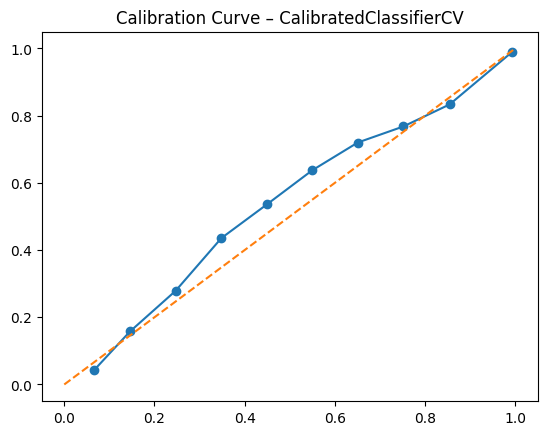

In [129]:
from sklearn.calibration import calibration_curve
prob_true, prob_pred = calibration_curve(y_test['result_name'], yhat_test, n_bins=10)

import matplotlib.pyplot as plt
plt.plot(prob_pred, prob_true, marker='o')
plt.plot([0,1],[0,1],"--")
plt.title("Calibration Curve – CalibratedClassifierCV")
plt.show()


Top 30 features por ganho (total_gain):
                                total_gain
dx_a0                         1.514978e+06
actiontype_receival_a0        1.290134e+06
dist_to_goal_a0               5.543558e+05
team_1                        4.328628e+05
x_a0                          4.180328e+05
time_delta_1                  4.037307e+05
actiontype_pass_a1            3.453914e+05
dy_a0                         2.875539e+05
actiontype_tackle_a0          2.636022e+05
angle_to_goal_a0              2.621905e+05
actiontype_pass_a0            1.877033e+05
y_a0                          1.795180e+05
actiontype_clearance_a1       1.750235e+05
defensive_compaction_x        1.705640e+05
actiontype_take_on_a0         1.610609e+05
dx_a1                         1.498323e+05
time_delta_2                  1.408892e+05
pressao_posicional_ponderada  1.171436e+05
team_2                        1.116483e+05
bodypart_head_a0              1.091512e+05
defensive_compaction_y        1.072621e+05
dx_a2        

<Axes: title={'center': 'Top 10 Feature Importances (total_gain)'}>

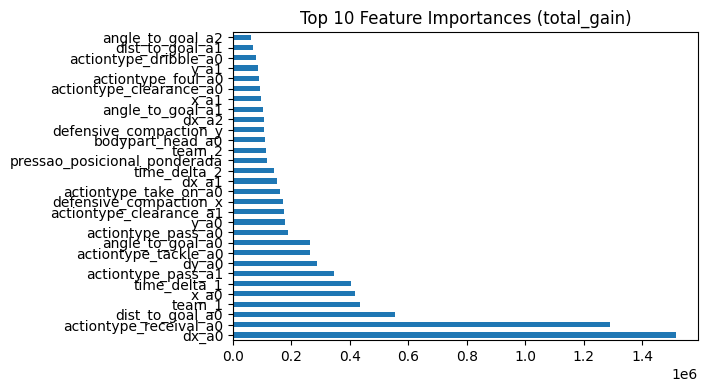

In [130]:
# Calcular feature importance da coluna success_score no modelo 'scores'
booster = classificador_sucesso.get_booster()
imp_dict = booster.get_score(importance_type='total_gain')

imp_df = (
    pd.DataFrame.from_dict(imp_dict, orient='index', columns=['total_gain'])
      .sort_values('total_gain', ascending=False)
)

print("\nTop 30 features por ganho (total_gain):")
print(imp_df.head(30))

# Visualização gráfica (opcional)
imp_df.head(30).plot.barh(figsize=(6,4), legend=False, title="Top 10 Feature Importances (total_gain)")



Probabilidade média de sucesso por tipo de ação (terminando em _a0):
                                mean_success_prob
actiontype_clearance_a0                  0.998306
actiontype_dribble_a0                    0.998305
actiontype_take_on_a0                    0.998296
actiontype_keeper_save_a0                0.998106
actiontype_receival_a0                   0.972412
actiontype_pass_a0                       0.795629
actiontype_tackle_a0                     0.424285
actiontype_shot_a0                       0.104551
actiontype_foul_a0                       0.053790
actiontype_cross_a0                           NaN
actiontype_throw_in_a0                        NaN
actiontype_freekick_crossed_a0                NaN
actiontype_freekick_short_a0                  NaN
actiontype_corner_crossed_a0                  NaN
actiontype_corner_short_a0                    NaN
actiontype_interception_a0                    NaN
actiontype_shot_penalty_a0                    NaN
actiontype_shot_freekick_a0   

<Axes: title={'center': 'Probabilidade média de sucesso por ActionType (_a0)'}>

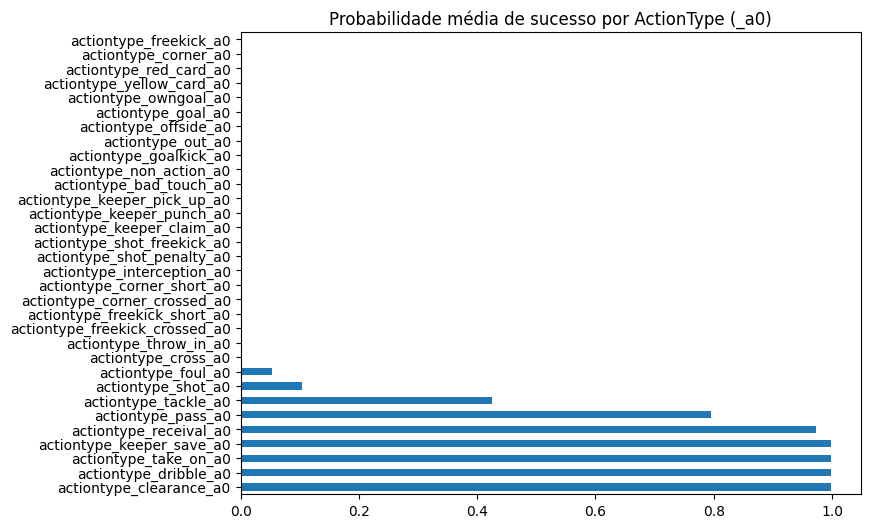

In [131]:
# 1. Filtrar colunas que começam com 'actiontype_' e terminam com '_a0'
actiontype_cols = [
    col for col in Xcs_val.columns
    if col.startswith('actiontype_') and col.endswith('_a0')
]

# 2. Calcular a média da probabilidade de sucesso para cada coluna
actiontype_probs = {}

for col in actiontype_cols:
    mask = Xcs_val[col] == 1
    if mask.sum() > 0:
        actiontype_probs[col] = yhat_val[mask].mean()
    else:
        actiontype_probs[col] = float('nan')  # Sem ocorrência

# 3. Converter para DataFrame e ordenar
actiontype_df = pd.DataFrame.from_dict(actiontype_probs, orient='index', columns=['mean_success_prob'])
actiontype_df = actiontype_df.sort_values('mean_success_prob', ascending=False)

# 4. Exibir
print("\nProbabilidade média de sucesso por tipo de ação (terminando em _a0):")
print(actiontype_df)

# 5. (Opcional) Visualizar
actiontype_df.plot.barh(figsize=(8, 6), legend=False, title="Probabilidade média de sucesso por ActionType (_a0)")


---

## Atomic VAEP + Classificador_sucesso

In [143]:
## Scores
train_score = calib.predict_proba(X_train_enriquecido)[:, 1]
test_score = calib.predict_proba(X_test_enriquecido)[:, 1]
len(train_score)

413361

In [144]:
X_train['success_score'] = train_score
X_test['success_score'] = test_score

In [145]:
# X_train['shot_value'] = X_train['success_score'] * X_train['actiontype_shot_a0']
# X_test['shot_value'] = X_test['success_score'] * X_test['actiontype_shot_a0']

# drop shot value
X_train.drop(columns=['shot_value'], inplace=True, errors='ignore')
X_test.drop(columns=['shot_value'], inplace=True, errors='ignore')

In [146]:
X_train

,actiontype_pass_a0,actiontype_cross_a0,actiontype_throw_in_a0,actiontype_freekick_crossed_a0,actiontype_freekick_short_a0,actiontype_corner_crossed_a0,actiontype_corner_short_a0,actiontype_take_on_a0,actiontype_foul_a0,actiontype_tackle_a0,...,time_seconds_overall_a0,period_id_a1,time_seconds_a1,time_seconds_overall_a1,period_id_a2,time_seconds_a2,time_seconds_overall_a2,time_delta_1,time_delta_2,success_score
0,True,False,False,False,False,False,False,False,False,False,...,153.887,1.0,153.887,153.887,1.0,153.887,153.887,0.000,0.000,0.998275
1,False,False,False,False,False,False,False,False,False,False,...,155.255,1.0,153.887,153.887,1.0,153.887,153.887,1.368,1.368,0.998187
2,True,False,False,False,False,False,False,False,False,False,...,156.623,1.0,155.255,155.255,1.0,153.887,153.887,1.368,2.736,0.106232
3,False,False,False,False,False,False,False,False,False,True,...,159.860,1.0,156.623,156.623,1.0,155.255,155.255,3.237,4.605,0.090452
4,False,False,False,False,False,False,False,False,False,False,...,159.893,1.0,159.860,159.860,1.0,156.623,156.623,0.033,3.270,0.998307
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413356,False,False,False,False,False,False,False,False,False,True,...,8767.134,2.0,6064.331,8764.331,2.0,6063.063,8763.063,2.803,4.071,0.695289
413357,True,False,False,False,False,False,False,False,False,False,...,8795.830,2.0,6067.134,8767.134,2.0,6064.331,8764.331,28.696,31.499,0.086091
413358,False,False,False,False,False,False,False,False,False,True,...,8798.732,2.0,6095.830,8795.830,2.0,6067.134,8767.134,2.902,31.598,0.989964
413359,True,False,False,False,False,False,False,False,False,False,...,8798.765,2.0,6098.732,8798.732,2.0,6095.830,8795.830,0.033,2.935,0.085407


In [147]:
print("\n### TREINANDO MODELO VAEP FINAL (com success_score) ###")
final_vaep_models = {}
for target in ['scores', 'concedes']:
    clf = XGBClassifier(
        n_estimators=800,
        max_depth=7,
        enable_categorical=True,
        n_jobs=-3,
        reg_lambda=1.0,
        subsample=0.6,
        learning_rate=0.01,
        colsample_bytree=0.6,
        random_state=42
    )
    clf.fit(X_train, y_train[target])
    final_vaep_models[target] = clf
    
    yhat_train = clf.predict_proba(X_train)[:, 1]
    yhat_test = clf.predict_proba(X_test)[:, 1]
    evaluate(y_train[target], yhat_train, label=f"FINAL VAEP {target} - TRAIN")
    evaluate(y_test[target], yhat_test, label=f"FINAL VAEP {target} - TEST")


### TREINANDO MODELO VAEP FINAL (com success_score) ###
### FINAL VAEP SCORES - TRAIN ###
  Brier score : 0.00991 (0.81975)
  Log loss    : 0.04443 (0.67252)
  ROC AUC     : 0.92396

### FINAL VAEP SCORES - TEST ###
  Brier score : 0.00957 (0.90919)
  Log loss    : 0.04862 (0.82540)
  ROC AUC     : 0.81564

### FINAL VAEP CONCEDES - TRAIN ###
  Brier score : 0.00204 (0.84855)
  Log loss    : 0.00949 (0.56026)
  ROC AUC     : 0.98649

### FINAL VAEP CONCEDES - TEST ###
  Brier score : 0.00175 (0.99180)
  Log loss    : 0.01156 (0.88961)
  ROC AUC     : 0.80790



---

## Feature Importance no VAEP


Top 10 features por ganho (total_gain):
                       total_gain
dist_to_goal_a0     107144.164062
success_score        69392.703125
x_a0                 49911.984375
actiontype_shot_a0   44379.949219
y_a0                 21970.720703
time_delta_1         21804.339844
dist_to_goal_a1      21788.300781
angle_to_goal_a0     21749.826172
dx_a0                18551.664062
time_seconds_a0      17989.402344

Importância de success_score: 69392.7031


<Axes: title={'center': 'Top 10 Feature Importances (total_gain)'}>

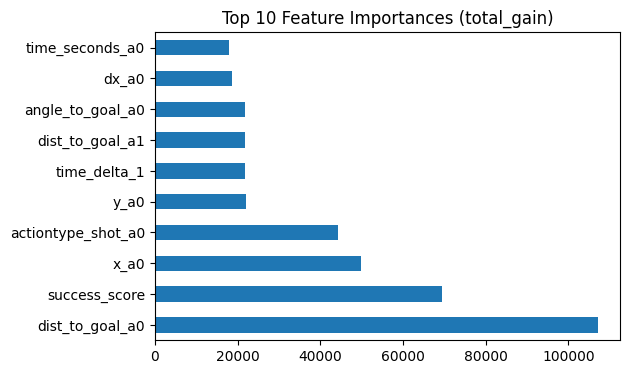

In [148]:
# ─────────── AQUI ───────────
# Calcular feature importance da coluna success_score no modelo 'scores'
scores_model = final_vaep_models['scores']
booster = scores_model.get_booster()
imp_dict = booster.get_score(importance_type='total_gain')

import pandas as pd
imp_df = (
    pd.DataFrame.from_dict(imp_dict, orient='index', columns=['total_gain'])
      .sort_values('total_gain', ascending=False)
)
print("\nTop 10 features por ganho (total_gain):")
print(imp_df.head(10))

if 'success_score' in imp_df.index:
    print(f"\nImportância de success_score: {imp_df.loc['success_score','total_gain']:.4f}")
else:
    print("\nA coluna 'success_score' não apareceu entre as features usadas (verifique se ela está em X_train).")

# Se quiser visualizar graficamente:
imp_df.head(10).plot.barh(figsize=(6,4), legend=False, title="Top 10 Feature Importances (total_gain)")

---

# Diagnóstico Visual dos Modelos Finais

In [149]:
Y_hat_train_final = pd.DataFrame()
Y_hat_test_final = pd.DataFrame()

for target in ['scores', 'concedes']:
    # Usamos os modelos do 'final_vaep_models' para prever nos conjuntos de treino e teste
    # Note que X_train e X_test aqui são os que contêm a coluna 'success_score'
    Y_hat_train_final[target] = final_vaep_models[target].predict_proba(X_train)[:, 1]
    Y_hat_test_final[target] = final_vaep_models[target].predict_proba(X_test)[:, 1]

print("Predições dos modelos finais coletadas.")

Predições dos modelos finais coletadas.


In [150]:
# %%
# --- ETAPA 9.2: Definição da Função de Plotagem ---
# (Esta é a sua função, copiada aqui para manter a célula autocontida)

def plot_model_diagnostics(y_train, y_test, yhat_train, yhat_test, label):
    """
    Plota curva de calibração, curva ROC e distribuição de probabilidades previstas.
    """
    plt.figure(figsize=(18, 5))

    # -------- Curva de Calibração --------
    plt.subplot(1, 3, 1)
    prob_true_train, prob_pred_train = calibration_curve(y_train, yhat_train, n_bins=10, strategy='uniform')
    prob_true_test, prob_pred_test = calibration_curve(y_test, yhat_test, n_bins=10, strategy='uniform')

    plt.plot(prob_pred_train, prob_true_train, marker='o', label='Treino')
    plt.plot(prob_pred_test, prob_true_test, marker='s', label='Teste')
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
    plt.title(f'Curva de Calibração - {label}')
    plt.xlabel('Probabilidade Prevista')
    plt.ylabel('Frequência Real')
    plt.legend()
    plt.grid(True)

    # -------- Curva ROC --------
    plt.subplot(1, 3, 2)
    fpr_train, tpr_train, _ = roc_curve(y_train, yhat_train)
    fpr_test, tpr_test, _ = roc_curve(y_test, yhat_test)

    auc_train = roc_auc_score(y_train, yhat_train)
    auc_test = roc_auc_score(y_test, yhat_test)

    plt.plot(fpr_train, tpr_train, label=f'Treino (AUC={auc_train:.5f})')
    plt.plot(fpr_test, tpr_test, label=f'Teste (AUC={auc_test:.5f})')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.title(f'Curva ROC - {label}')
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.legend()
    plt.grid(True)

    # -------- Distribuição das Probabilidades Previstas --------
    plt.subplot(1, 3, 3)
    sns.kdeplot(yhat_train, label='Treino', fill=True)
    sns.kdeplot(yhat_test, label='Teste', fill=True)
    plt.title(f'Distribuição de Probabilidades - {label}')
    plt.xlabel('Probabilidade prevista')
    plt.ylabel('Densidade')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


### GRÁFICOS DE DIAGNÓSTICO PARA OS MODELOS VAEP FINAIS ###



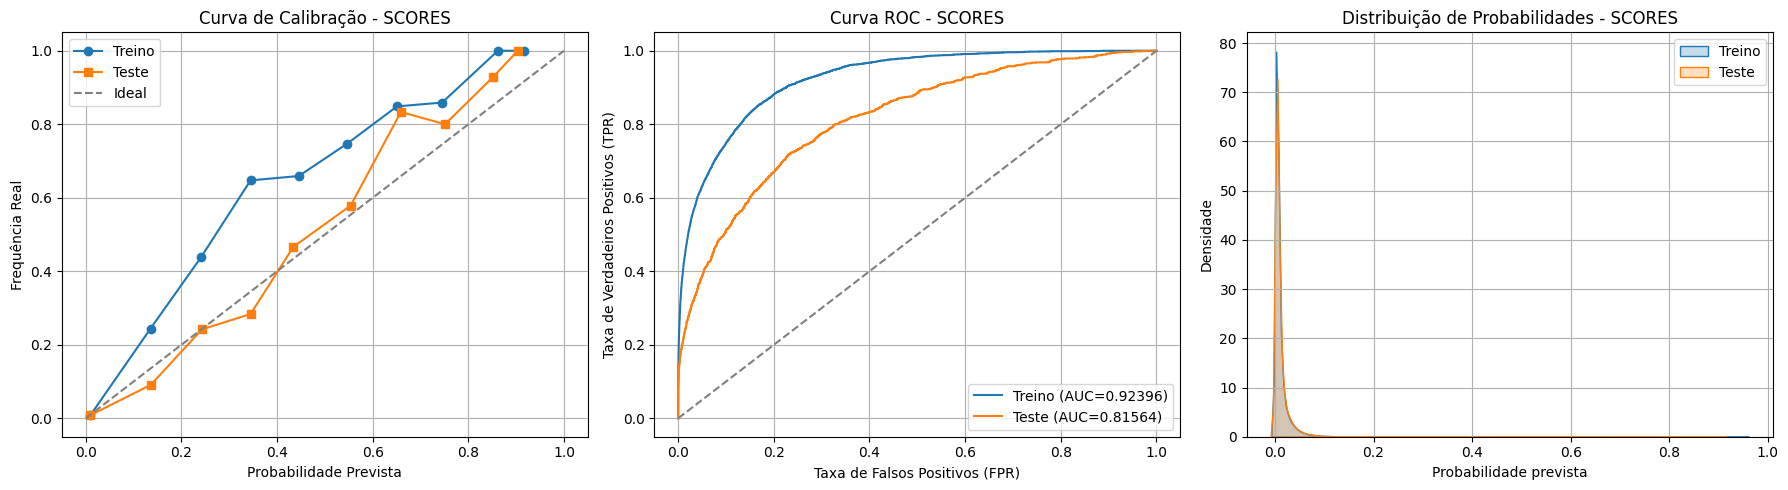

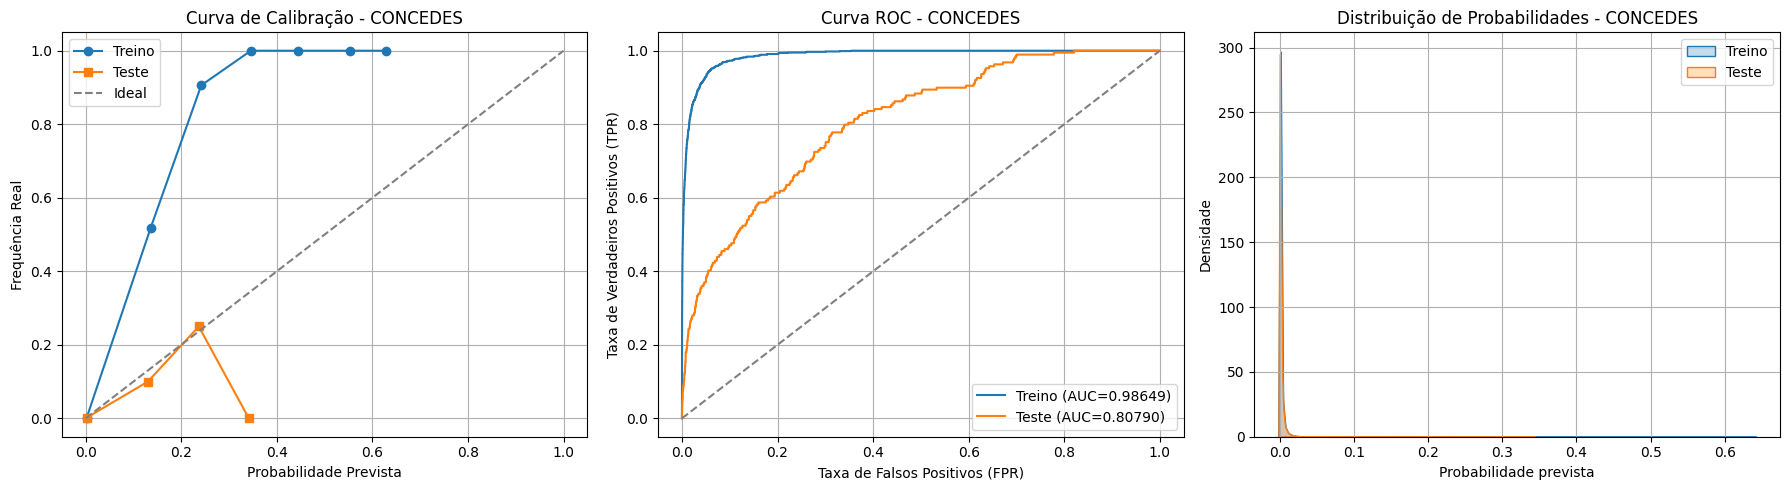

In [151]:
print("\n### GRÁFICOS DE DIAGNÓSTICO PARA OS MODELOS VAEP FINAIS ###\n")

for col in ['scores', 'concedes']:
    plot_model_diagnostics(
        y_train[col], 
        y_test[col], 
        Y_hat_train_final[col], 
        Y_hat_test_final[col], 
        label=col.upper()
    )

In [152]:
df_atomic

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id,type_name,result_name
0,13335,12926009,0,1,153.887,5.0,15620,52.826,34.309,-18.499,-4.643,0,5,pass,success
1,13335,12926009,1,1,155.255,5.0,4696,34.327,29.666,0.000,0.000,23,0,receival,success
2,13335,12926647,2,1,156.623,5.0,4696,34.623,31.107,45.198,18.914,0,5,pass,fail
3,13335,12926642,3,1,159.860,5.0,14278,79.821,50.021,NaN,NaN,9,0,tackle,fail
4,13335,20246849,4,1,159.893,11.0,284,25.179,17.979,18.809,-10.268,18,0,clearance,success
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520056,13621,18803885,601140,2,6067.134,218.0,102,65.365,58.755,NaN,NaN,9,0,tackle,success
520057,13621,18803906,601141,2,6095.830,218.0,102,75.750,54.667,20.560,-30.762,0,5,pass,fail
520058,13621,18803919,601142,2,6098.732,218.0,567,96.310,23.905,NaN,NaN,9,0,tackle,success
520059,13621,18803920,601143,2,6098.765,218.0,567,96.432,23.710,5.675,8.382,0,1,pass,fail


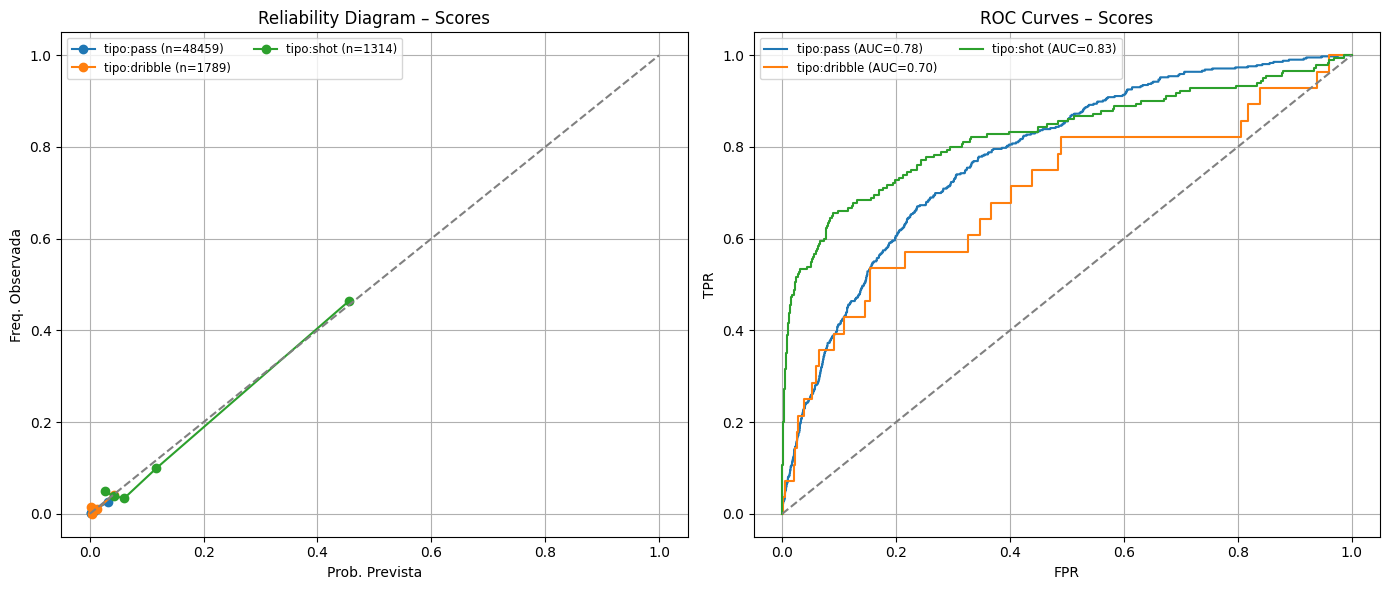

Segment     |   Brier    | Rel. Brier |  ROC AUC
------------|------------|------------|---------
tipo:pass  |   0.00841 |     0.008 |   0.782
tipo:dribble |   0.01517 |     0.015 |   0.700
tipo:shot  |   0.07466 |     0.087 |   0.828


In [153]:
# %% [markdown]
# ## Avaliação Segmentada por Tipo de Ação e Zona do Campo

# %% 
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.calibration import calibration_curve

# 1) Defina seus segmentos de interesse
#    usamos df_atomic.reset_index() para alinhar com X_test e Y_hat_test_final
df_eval = df_atomic.reset_index(drop=True).loc[mask_test].copy()
df_eval['y_true']  = y_test['scores'].values
df_eval['y_pred']  = Y_hat_test_final['scores'].values

# 1a) Tipos de ação
action_types = ['pass', 'dribble', 'shot']


segments = {
    **{f"tipo:{a}": df_eval['type_name']==a for a in action_types}
}

# 2) Para cada segmento, calcule métrica e plote Curva de Calibração e ROC
plt.figure(figsize=(14, 6))

# 2a) Calibração por segmento
plt.subplot(1,2,1)
for name, mask in segments.items():
    y_true_seg = df_eval.loc[mask, 'y_true']
    y_pred_seg = df_eval.loc[mask, 'y_pred']
    if len(y_true_seg)==0: continue
    prob_true, prob_pred = calibration_curve(y_true_seg, y_pred_seg, n_bins=5, strategy='quantile')
    plt.plot(prob_pred, prob_true, marker='o', label=f"{name} (n={len(y_true_seg)})")
plt.plot([0,1],[0,1],'--', color='gray')
plt.title("Reliability Diagram – Scores")
plt.xlabel("Prob. Prevista")
plt.ylabel("Freq. Observada")
plt.legend(fontsize='small', ncol=2)
plt.grid(True)

# 2b) ROC por segmento
plt.subplot(1,2,2)
for name, mask in segments.items():
    y_true_seg = df_eval.loc[mask, 'y_true']
    y_pred_seg = df_eval.loc[mask, 'y_pred']
    if len(y_true_seg)==0: continue
    auc = roc_auc_score(y_true_seg, y_pred_seg)
    fpr, tpr, _ = roc_curve(y_true_seg, y_pred_seg)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.2f})")
plt.plot([0,1],[0,1],'--', color='gray')
plt.title("ROC Curves – Scores")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend(fontsize='small', ncol=2)
plt.grid(True)

plt.tight_layout()
plt.show()

# 3) Métricas numéricas: Brier + AUC por segmento
print("Segment     |   Brier    | Rel. Brier |  ROC AUC")
print("------------|------------|------------|---------")
p = df_eval['y_true'].mean()
for name, mask in segments.items():
    y_true_seg = df_eval.loc[mask, 'y_true']
    y_pred_seg = df_eval.loc[mask, 'y_pred']
    if len(y_true_seg)==0: continue
    b   = brier_score_loss(y_true_seg, y_pred_seg)
    base= brier_score_loss(y_true_seg, np.full_like(y_true_seg, p))
    auc = roc_auc_score(y_true_seg, y_pred_seg)
    print(f"{name:10s} | {b:9.5f} | {b/base:9.3f} | {auc:7.3f}")
